<a href="https://colab.research.google.com/github/PsicoJazz/Analise_de_Dados_Doencas_Cronicas_Marilia-SP/blob/main/An%C3%A1lise_de_Dados_Doen%C3%A7as_Cronicas_em_Mar%C3%ADlia_SP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


In [8]:
dadosMarilia = pd.read_excel("dados_marilia_dashboard.xlsx")
print(dadosMarilia.head())

  data_ocorrencia nome_municipio  \
0      2024-01-20        Marília   
1      2024-01-20        Marília   
2      2024-01-20        Marília   
3      2024-01-30        Marília   
4      2024-01-30        Marília   

                                doenca_cronica_grupo causa_principal_cid  \
0                                  Diabetes Mellitus                E112   
1                              Doenças Hipertensivas                I110   
2  Outras Doenças Crônicas Cardiovasculares/Metab...                I500   
3  Outras Doenças Crônicas Cardiovasculares/Metab...                I740   
4     Doenças Isquêmicas do Coração (Infarto/Angina)                I219   

   idade     genero raca_cor    local_ocorrencia teve_assistencia_medica  
0     81   Feminino  Amarela            Hospital                     Sim  
1     68  Masculino    Parda            Hospital                     Sim  
2     81   Feminino   Branca  Outro Estab. Saúde           Não Informado  
3     88   Feminino   Bran

**Incidencia de casos entre Homens e Mulheres**

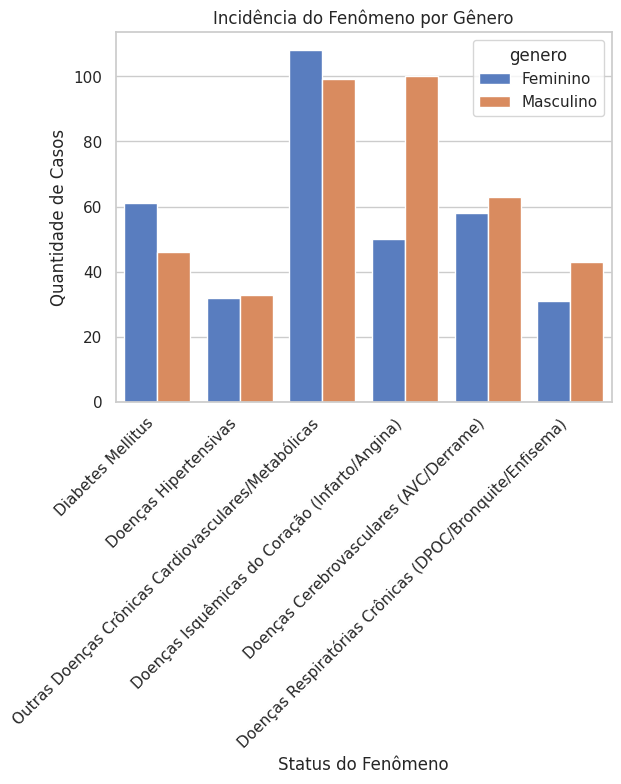

In [9]:
sns.set_theme(style="whitegrid")

# Cria o gráfico de contagem
sns.countplot(data=dadosMarilia, x="doenca_cronica_grupo", hue="genero", palette="muted")

# Customização de títulos
plt.title("Incidência do Fenômeno por Gênero")
plt.xlabel("Status do Fenômeno")
plt.ylabel("Quantidade de Casos")

plt.xticks(rotation=45, ha="right")


# Exibe o gráfico
plt.show()

**Procura de tratamento**

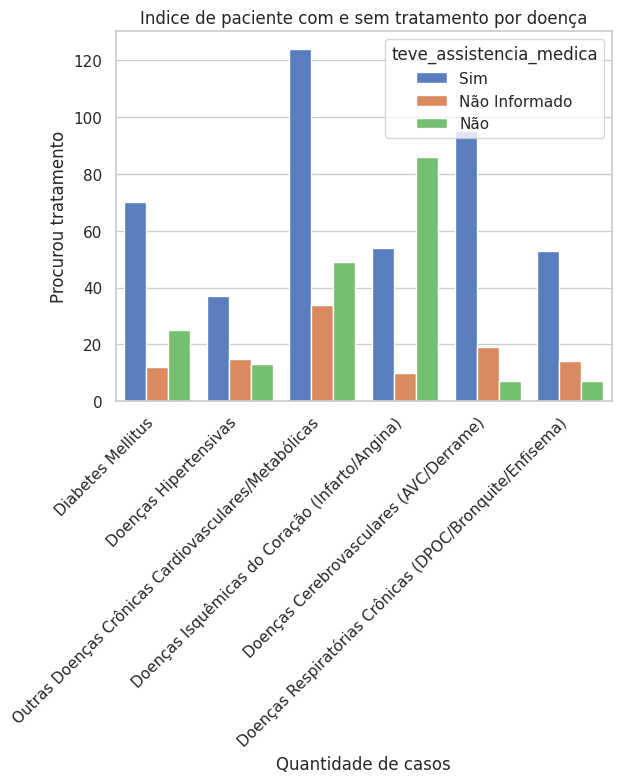

In [10]:
sns.set_theme(style="whitegrid")

# Cria o gráfico de contagem
sns.countplot(data=dadosMarilia, x="doenca_cronica_grupo", hue="teve_assistencia_medica", palette="muted")

# Customização de títulos
plt.title("Indice de paciente com e sem tratamento por doença")
plt.xlabel("Quantidade de casos")
plt.ylabel("Procurou tratamento")

plt.xticks(rotation=45, ha="right")


# Exibe o gráfico
plt.show()

**Porcentagem na procura de tratamento**

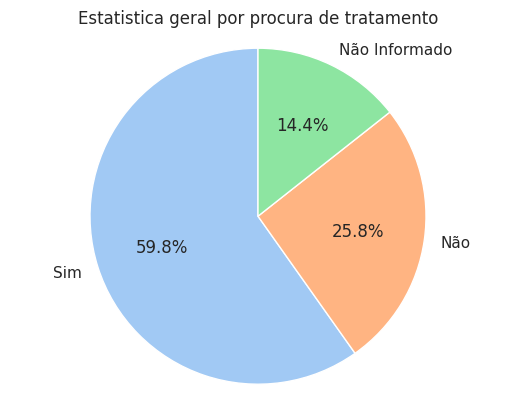

In [11]:
dados_pizza = dadosMarilia["teve_assistencia_medica"].value_counts()

# 2. Define as cores usando uma paleta do Seaborn (ex: 'pastel', 'muted', 'Set2')
cores = sns.color_palette("pastel")[0:len(dados_pizza)]

# 3. Cria o gráfico de pizza
plt.pie(
    dados_pizza,
    labels=dados_pizza.index,       # Nomes das fatias
    autopct="%1.1f%%",              # Mostra a porcentagem com 1 casa decimal
    startangle=90,                  # Rotaciona o gráfico para começar no topo
    colors=cores                    # Aplica as cores do Seaborn
)

# Garante que a pizza seja desenhada como um círculo perfeito
plt.axis("equal")

plt.title("Estatistica geral por procura de tratamento")
plt.show()

**Quantidade de casos em relação a população total**

--- Tabela Estimativa de Impacto em Relação ao Município (240.000 hab) ---


,Doença Crônica,Casos na Amostra,Porcentagem da População (%)
0,Outras Doenças Crônicas Cardiovasculares/Metab...,207,0.086250
1,Doenças Isquêmicas do Coração (Infarto/Angina),150,0.062500
2,Doenças Cerebrovasculares (AVC/Derrame),121,0.050417
3,Diabetes Mellitus,107,0.044583
4,Doenças Respiratórias Crônicas (DPOC/Bronquite...,74,0.030833
5,Doenças Hipertensivas,65,0.027083


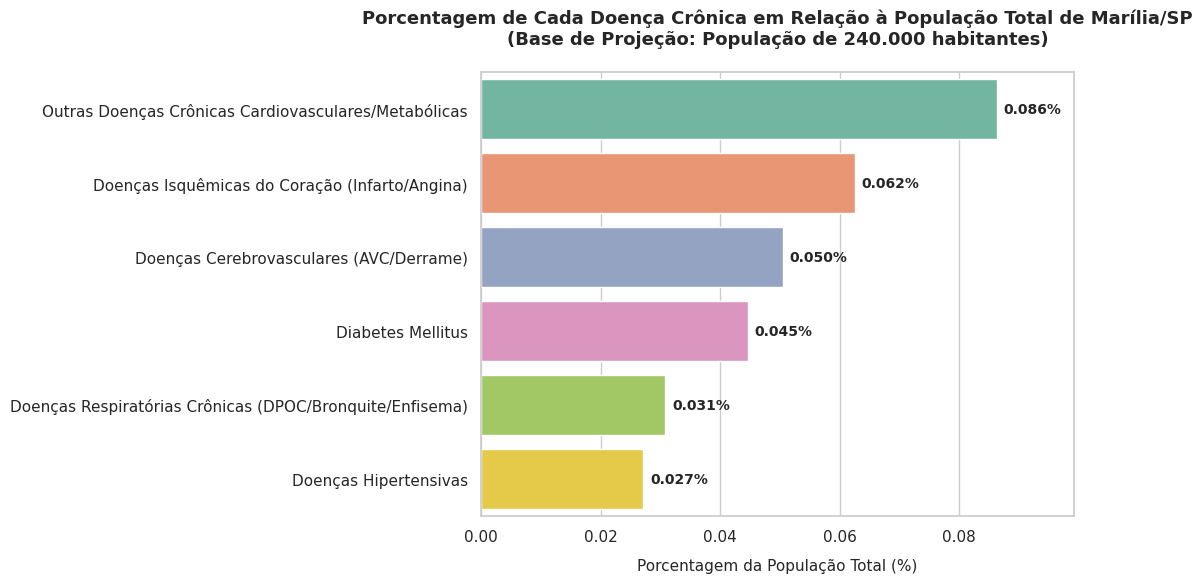

In [12]:


# 1. Definição da população de Marília
populacao_marilia = 240000

# 2. Contagem de casos por grupo de doença na tabela
coluna_alvo = "doenca_cronica_grupo"
contagem_casos = dadosMarilia[coluna_alvo].value_counts().reset_index()
contagem_casos.columns = ["Doença Crônica", "Casos na Amostra"]

# 3. Calcular a porcentagem de cada doença em relação à população total do município (240k)
contagem_casos["Porcentagem da População (%)"] = (contagem_casos["Casos na Amostra"] / populacao_marilia) * 100

# Exibir a tabela com as estimativas completas para acompanhamento
print("--- Tabela Estimativa de Impacto em Relação ao Município (240.000 hab) ---")
display(contagem_casos)

# 4. Gerar o gráfico mostrando APENAS as doenças para melhor escala visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

grafico = sns.barplot(
    data=contagem_casos,
    y="Doença Crônica",
    x="Porcentagem da População (%)",
    hue="Doença Crônica",
    palette="Set2",
    legend=False
)

# Adicionar as etiquetas de porcentagem no final de cada barra
for container in grafico.containers:
    grafico.bar_label(container, fmt="%.3f%%", padding=5, fontsize=10, weight='bold')

plt.title("Porcentagem de Cada Doença Crônica em Relação à População Total de Marília/SP\n(Base de Projeção: População de 240.000 habitantes)", fontsize=13, pad=20, weight='bold')
plt.xlabel("Porcentagem da População Total (%)", fontsize=11, labelpad=10)
plt.ylabel("")

# Define um limite dinâmico no eixo X para dar espaço aos rótulos de texto
plt.xlim(0, contagem_casos["Porcentagem da População (%)"].max() * 1.15)

plt.tight_layout()
plt.show()

**Incidencia por genero e idade**

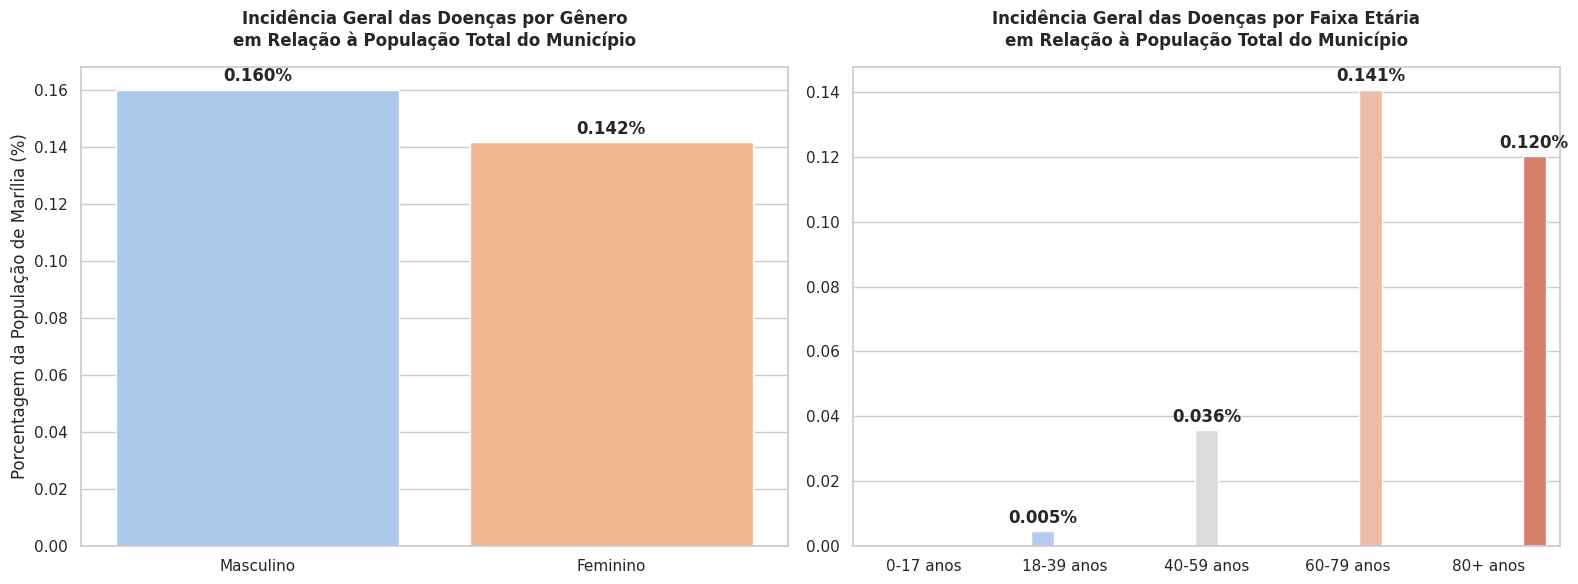


--- TABELA DE ESTIMATIVA POR GÊNERO ---


,Gênero,Casos na Amostra,Porcentagem do Município (%)
0,Masculino,384,0.160000
1,Feminino,340,0.141667



--- TABELA DE ESTIMATIVA POR FAIXA ETÁRIA ---


,Faixa Etária,Casos na Amostra,Porcentagem do Município (%)
0,18-39 anos,11,0.004583
1,40-59 anos,86,0.035833
2,60-79 anos,338,0.140833
3,80+ anos,289,0.120417


In [13]:


populacao_marilia = 240000

# --- 1. SEGMENTAÇÃO POR GÊNERO ---
contagem_genero = dadosMarilia["genero"].value_counts().reset_index()
contagem_genero.columns = ["Gênero", "Casos na Amostra"]
contagem_genero["Porcentagem do Município (%)"] = (contagem_genero["Casos na Amostra"] / populacao_marilia) * 100

# --- 2. SEGMENTAÇÃO POR FAIXA ETÁRIA ---
# Criando faixas etárias para melhor visualização
def agrupar_idade(idade):
    if idade < 18:
        return "0-17 anos"
    elif idade < 40:
        return "18-39 anos"
    elif idade < 60:
        return "40-59 anos"
    elif idade < 80:
        return "60-79 anos"
    else:
        return "80+ anos"

dadosMarilia["faixa_etaria"] = dadosMarilia["idade"].apply(agrupar_idade)
contagem_idade = dadosMarilia["faixa_etaria"].value_counts().reset_index()
contagem_idade.columns = ["Faixa Etária", "Casos na Amostra"]
ordem_idades = ["0-17 anos", "18-39 anos", "40-59 anos", "60-79 anos", "80+ anos"]
contagem_idade["Faixa Etária"] = pd.Categorical(contagem_idade["Faixa Etária"], categories=ordem_idades, ordered=True)
contagem_idade = contagem_idade.sort_values("Faixa Etária").reset_index(drop=True)
contagem_idade["Porcentagem do Município (%)"] = (contagem_idade["Casos na Amostra"] / populacao_marilia) * 100

# --- plotagem dos gráficos ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico por Gênero
grafico_gen = sns.barplot(
    data=contagem_genero,
    x="Gênero",
    y="Porcentagem do Município (%)",
    hue="Gênero",
    palette="pastel",
    ax=axes[0],
    legend=False
)
for container in grafico_gen.containers:
    grafico_gen.bar_label(container, fmt="%.3f%%", padding=3, weight='bold')
axes[0].set_title("Incidência Geral das Doenças por Gênero\nem Relação à População Total do Município", fontsize=12, weight='bold', pad=15)
axes[0].set_ylabel("Porcentagem da População de Marília (%)")
axes[0].set_xlabel("")

# Gráfico por Faixa Etária
grafico_id = sns.barplot(
    data=contagem_idade,
    x="Faixa Etária",
    y="Porcentagem do Município (%)",
    hue="Faixa Etária",
    palette="coolwarm",
    ax=axes[1],
    legend=False
)
for container in grafico_id.containers:
    grafico_id.bar_label(container, fmt="%.3f%%", padding=3, weight='bold')
axes[1].set_title("Incidência Geral das Doenças por Faixa Etária\nem Relação à População Total do Município", fontsize=12, weight='bold', pad=15)
axes[1].set_ylabel("")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

# Apresentar as tabelas estimadas
print("\n--- TABELA DE ESTIMATIVA POR GÊNERO ---")
display(contagem_genero)
print("\n--- TABELA DE ESTIMATIVA POR FAIXA ETÁRIA ---")
display(contagem_idade)

--- Estatísticas de Idade por Grupo de Doença ---


,Doença Crônica,Nº de Casos,Idade Média,Idade Mediana,Desvio Padrão
4,Doenças Respiratórias Crônicas (DPOC/Bronquite...,74,78.445946,79.0,11.807986
2,Doenças Hipertensivas,65,76.646154,79.0,14.046164
1,Doenças Cerebrovasculares (AVC/Derrame),121,75.942149,79.0,11.599064
0,Diabetes Mellitus,107,74.457944,76.0,12.960958
5,Outras Doenças Crônicas Cardiovasculares/Metab...,207,72.845411,75.0,14.575057
3,Doenças Isquêmicas do Coração (Infarto/Angina),150,72.586667,74.0,13.942445



--- Análise Estatística ---
Resultado: Existe uma associação (correlação) estatisticamente significativa entre a idade e o tipo de doença crônica (p < 0.05).


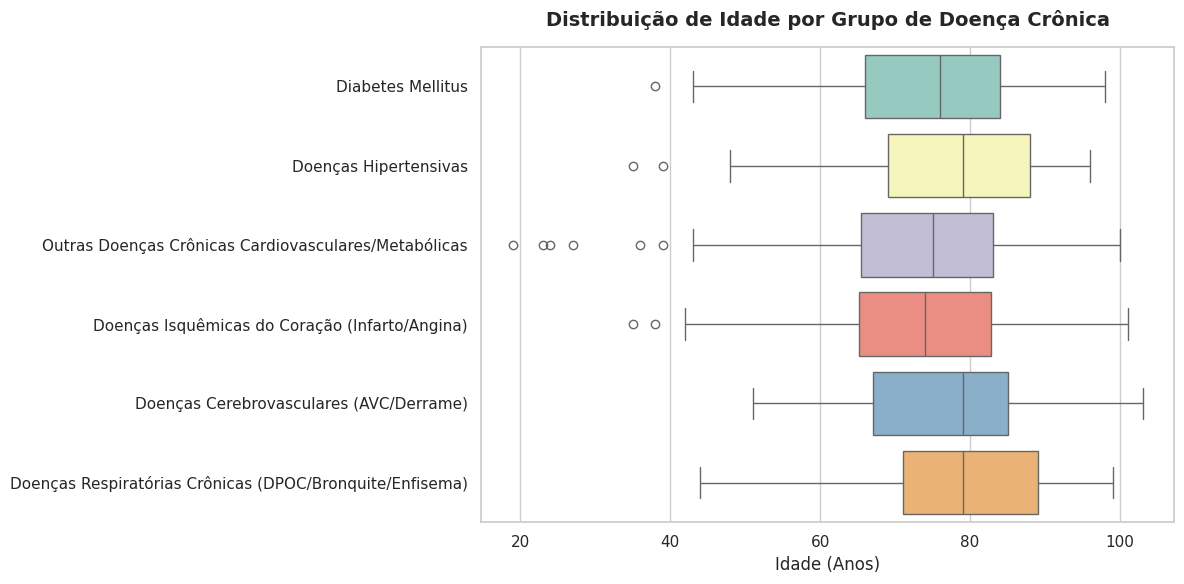

In [16]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupar os dados para ver a média e mediana de idade por doença
estatisticas_idade = dadosMarilia.groupby("doenca_cronica_grupo")["idade"].agg(["count", "mean", "median", "std"]).reset_index()
estatisticas_idade.columns = ["Doença Crônica", "Nº de Casos", "Idade Média", "Idade Mediana", "Desvio Padrão"]

print("--- Estatísticas de Idade por Grupo de Doença ---")
display(estatisticas_idade.sort_values(by="Idade Média", ascending=False))

# 2. Teste Estatístico (ANOVA) para verificar a associação/correlação
# Separando as idades por grupo de doença
grupos = [grupo["idade"].values for nome, grupo in dadosMarilia.groupby("doenca_cronica_grupo")]
f_stat, p_val = stats.f_oneway(*grupos)

print("\n--- Análise Estatística ---")

if p_val < 0.05:
    print("Resultado: Existe uma associação (correlação) estatisticamente significativa entre a idade e o tipo de doença crônica (p < 0.05).")
else:
    print("Resultado: Não há evidências de associação significativa entre a idade e o tipo de doença crônica (p >= 0.05).")

# 3. Gráfico Boxplot para visualização da relação
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

sns.boxplot(
    data=dadosMarilia,
    y="doenca_cronica_grupo",
    x="idade",
    hue="doenca_cronica_grupo",
    palette="Set3",
    legend=False
)

plt.title("Distribuição de Idade por Grupo de Doença Crônica", fontsize=14, pad=15, weight='bold')
plt.xlabel("Idade (Anos)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### **Exportação dos Resultados para Análise de Dados**

Nas próximas células, vamos organizar e exportar as principais tabelas estatísticas criadas e os gráficos gerados para arquivos externos, permitindo análises complementares ou elaboração de apresentações.

In [ ]:
import os

# Criando diretório dedicado para a exportação
os.makedirs('exportacao_analise', exist_ok=True)
print("Diretório 'exportacao_analise' criado com sucesso!")

In [17]:
import pandas as pd

# 1. Exportando os dados tabulares agregados para um único arquivo Excel consolidado
with pd.ExcelWriter('exportacao_analise/relatorio_analise_marilia.xlsx', engine='openpyxl') as writer:
    contagem_casos.to_excel(writer, sheet_name='Porcentagem Doencas', index=False)
    contagem_genero.to_excel(writer, sheet_name='Estimativa Genero', index=False)
    contagem_idade.to_excel(writer, sheet_name='Estimativa Idade', index=False)
    estatisticas_idade.to_excel(writer, sheet_name='Estatisticas Idade', index=False)

print("Planilha consolidada 'relatorio_analise_marilia.xlsx' exportada com sucesso contendo todas as abas!")

Planilha consolidada 'relatorio_analise_marilia.xlsx' exportada com sucesso contendo todas as abas!


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Gerando e exportando os gráficos em alta definição para a pasta de exportação

# Gráfico 1: Porcentagem de Doenças Crônicas
plt.figure(figsize=(11, 6))
grafico = sns.barplot(
    data=contagem_casos,
    y="Doença Crônica",
    x="Porcentagem da População (%)",
    hue="Doença Crônica",
    palette="Set2",
    legend=False
)
for container in grafico.containers:
    grafico.bar_label(container, fmt="%.3f%%", padding=5, fontsize=10, weight='bold')
plt.title("Porcentagem de Cada Doença Crônica em Relação à População Total de Marília/SP\n(Base de Projeção: População de 240.000 habitantes)", fontsize=13, pad=20, weight='bold')
plt.xlabel("Porcentagem da População Total (%)", fontsize=11, labelpad=10)
plt.ylabel("")
plt.xlim(0, contagem_casos["Porcentagem da População (%)"].max() * 1.15)
plt.tight_layout()
plt.savefig('exportacao_analise/grafico_doencas_porcentagem.png', dpi=300)
plt.close()

# Gráfico 2: Perfil por Gênero e Faixa Etária
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# Gênero
grafico_gen = sns.barplot(data=contagem_genero, x="Gênero", y="Porcentagem do Município (%)", hue="Gênero", palette="pastel", ax=axes[0], legend=False)
for container in grafico_gen.containers:
    grafico_gen.bar_label(container, fmt="%.3f%%", padding=3, weight='bold')
axes[0].set_title("Incidência Geral das Doenças por Gênero\nem Relação à População Total", fontsize=12, weight='bold', pad=15)
axes[0].set_ylabel("Porcentagem (%)")
# Idade
grafico_id = sns.barplot(data=contagem_idade, x="Faixa Etária", y="Porcentagem do Município (%)", hue="Faixa Etária", palette="coolwarm", ax=axes[1], legend=False)
for container in grafico_id.containers:
    grafico_id.bar_label(container, fmt="%.3f%%", padding=3, weight='bold')
axes[1].set_title("Incidência Geral das Doenças por Faixa Etária\nem Relação à População Total", fontsize=12, weight='bold', pad=15)
axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig('exportacao_analise/grafico_genero_idade_perfil.png', dpi=300)
plt.close()

# Gráfico 3: Distribuição de Idades por Doença
plt.figure(figsize=(12, 6))
sns.boxplot(data=dadosMarilia, y="doenca_cronica_grupo", x="idade", hue="doenca_cronica_grupo", palette="Set3", legend=False)
plt.title("Distribuição de Idade por Grupo de Doença Crônica", fontsize=14, pad=15, weight='bold')
plt.xlabel("Idade (Anos)")
plt.ylabel("")
plt.tight_layout()
plt.savefig('exportacao_analise/grafico_boxplot_distribuicao_idade.png', dpi=300)
plt.close()

print("Gráficos salvos com sucesso em formato PNG (300 DPI) na pasta 'exportacao_analise'!")

Gráficos salvos com sucesso em formato PNG (300 DPI) na pasta 'exportacao_analise'!
